# Econometria sui paesi: complessità e crescita del PIL

Schema standard della letteratura (Hidalgo & Hausmann 2009; Hausmann et al., *Atlas of Economic Complexity* 2011;
Tacchella et al. 2018): crescita annualizzata del PIL pro capite su un orizzonte di $T$ anni regredita sul livello
iniziale del PIL (convergenza) e sulla metrica di complessità iniziale.

$$g_{c,t} = \frac{\ln y_{c,t+T} - \ln y_{c,t}}{T} = \beta_0 + \beta_1 \ln y_{c,t} + \beta_2\, z_{c,t} + \gamma_t + \varepsilon_{c,t}$$

- $y$: PIL reale pro capite a PPP (Penn World Table 11.0, `rgdpna / pop`)
- $z$: metrica di complessità all'anno iniziale, trasformata (log per le metriche positive tipo fitness) e standardizzata
  per anno, così i coefficienti sono confrontabili fra metriche
- $\gamma_t$: effetti fissi di periodo; periodi non sovrapposti (T = 5: 2002, 2007, 2012, 2017; T = 10: 2002, 2012)
- errori standard clusterizzati per paese
- campione: paesi con popolazione iniziale ≥ `MIN_POP` milioni e tutte le metriche disponibili (stesso campione per tutti i modelli)

Il contributo di ogni metrica si legge nel coefficiente $\beta_2$ e nell'aumento di $R^2$ rispetto al modello con solo PIL iniziale.
I modelli "horse race" mettono insieme due metriche per vedere se la prima aggiunge informazione alla seconda:
estesa vs classica, e metrica vs $N_1$ medio del paniere di export (numero medio di input dei prodotti esportati).
Il confronto con $N_1$ medio verifica se il vantaggio delle metriche estese si riduce al solo "contare gli input".

Metriche da `results/econometria/metriche/4_digits/*/country/` e PIL da `results/econometria/misure_esterne/country/` (via `src/storage.py`). Tabelle in `results/econometria/regressioni/`, figure in `plots/econometria/econometria_paesi/`.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd

ROOT = next(p for p in [Path().resolve(), *Path().resolve().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))
import matplotlib.pyplot as plt
from src.plotting import (set_style, figsize, save_fig, two_part_legend, common_ylim,
                          SINGLE, HALF, PALETTE, RES_MARKER, SEQ_CMAP, SYMBOLS)

set_style()
from src.econometrics import ols, residualize
from src.storage import load_metrics_long, load_external_country

## Configurazione

In [2]:
RES = 4
HORIZONS = {5: [2002, 2007, 2012, 2017], 10: [2002, 2012]}     # anni iniziali, periodi non sovrapposti
MIN_POP = 1.0                                                # milioni di abitanti all'anno iniziale

# (metrica, variabile) nei file delle metriche -> nome, trasformazione
METRICS = {
    "extended_fitness": (("extended_fitness", "F"), "Extended Fitness", "log"),
    "extended_eci":     (("extended_eci", "F"),     "Extended ECI",     "log"),
    "fitness":     (("fitness", "F"),     "Fitness",        "log"),
    "eci":         (("eci", "ECI"),       "ECI",            "raw"),
    # controllo: numero medio di input dei prodotti esportati dal paese (con RCA), calcolato qui sotto
    "n1_medio":    (None,                 "N1 medio",       "log"),
}
HORSE_RACES = [("extended_fitness", "fitness"), ("extended_eci", "eci"),
               ("extended_fitness", "n1_medio"), ("extended_eci", "n1_medio"), ("fitness", "n1_medio")]

TAB_DIR = ROOT / "results" / "econometria" / "regressioni"
FIG_DIR = ROOT / "plots" / "econometria" / "econometria_paesi"
SAVE_FIGS = True
TAB_DIR.mkdir(parents=True, exist_ok=True)

## Dati

In [3]:
pwt = load_external_country()[["iso3", "year", "rgdpna", "pop", "lny"]]
pwt = pwt.dropna(subset=["rgdpna", "pop"]).set_index(["iso3", "year"])

m = load_metrics_long(RES, "country")
metrics_wide = pd.concat(
    {k: m[(m.metric == mv[0]) & (m.variable == mv[1])].set_index(["iso3", "year"])["value"]
     for k, (mv, _, _) in METRICS.items() if mv is not None}, axis=1)

# N_1 medio del paniere di export: media del numero di input sui prodotti che il paese esporta (M_cp = 1)
iso3 = pd.read_csv(ROOT / "data" / "raw" / "BACI" / "country_codes_V202601.csv").set_index("country_code")["country_iso3"]
base = ROOT / "data" / "HS02_all_years" / f"{RES}_digits" / "alligned" / "binarized"
N1 = pd.read_parquet(base / "C" / f"C_{RES}_digits_HS02.parquet").sum(axis=0)
rows = []
for year in sorted({t for s in HORIZONS.values() for t in s}):
    M = pd.read_parquet(base / "Mcp_export" / f"Mcp_export_alligned_Y{year}.parquet")
    n1 = (M.values @ N1.reindex(M.columns).values) / M.values.sum(axis=1)
    rows.append(pd.DataFrame({"iso3": M.index.map(iso3), "year": year, "n1_medio": n1}))
metrics_wide = metrics_wide.join(pd.concat(rows).set_index(["iso3", "year"]), how="left")

def panel(T, starts):
    rows = []
    for t0 in starts:
        d = metrics_wide.xs(t0, level="year").copy()
        d["lny0"] = pwt["lny"].xs(t0, level="year").reindex(d.index)
        d["lny1"] = pwt["lny"].xs(t0 + T, level="year").reindex(d.index)
        d["pop0"] = pwt["pop"].xs(t0, level="year").reindex(d.index)
        d = d.dropna()
        d = d[d["pop0"] >= MIN_POP]
        for k, (_, _, tr) in METRICS.items():
            x = np.log(d[k]) if tr == "log" else d[k]
            d[f"z_{k}"] = (x - x.mean()) / x.std()           # standardizzazione nel periodo
        d["g"] = 100 * (d["lny1"] - d["lny0"]) / T            # crescita annua, in %
        d["period"] = t0
        rows.append(d.reset_index())
    return pd.concat(rows, ignore_index=True)

panels = {T: panel(T, s) for T, s in HORIZONS.items()}
for T, d in panels.items():
    print(f"T = {T}: {len(d)} osservazioni, {d.iso3.nunique()} paesi, periodi {sorted(d.period.unique())}")

T = 5: 591 osservazioni, 150 paesi, periodi [2002, 2007, 2012, 2017]
T = 10: 293 osservazioni, 149 paesi, periodi [2002, 2012]


## Regressioni

In [4]:
def fit(d, regressors):
    return ols(d, "g", ["lny0"] + regressors, fixed_effects=["period"], cluster="iso3")

results = []
for T, d in panels.items():
    base = fit(d, [])
    results.append({"T": T, "modello": "solo PIL iniziale", "R2": base.rsquared, "dR2": 0.0, "N": int(base.nobs),
                    "b_lny0": base.params["lny0"], "se_lny0": base.bse["lny0"]})
    specs = [(METRICS[k][1], [k]) for k in METRICS] + \
            [(f"{METRICS[a][1]} + {METRICS[b][1]}", [a, b]) for a, b in HORSE_RACES]
    for name, ks in specs:
        r = fit(d, [f"z_{k}" for k in ks])
        row = {"T": T, "modello": name, "R2": r.rsquared, "dR2": r.rsquared - base.rsquared, "N": int(r.nobs),
               "b_lny0": r.params["lny0"], "se_lny0": r.bse["lny0"]}
        for k in ks:
            row[f"b_{k}"], row[f"se_{k}"], row[f"p_{k}"] = r.params[f"z_{k}"], r.bse[f"z_{k}"], r.pvalues[f"z_{k}"]
        results.append(row)

res = pd.DataFrame(results)
res.to_csv(TAB_DIR / "regressioni.csv", index=False)
res.round(3)

,T,modello,R2,dR2,N,b_lny0,se_lny0,b_extended_fitness,se_extended_fitness,p_extended_fitness,...,p_extended_eci,b_fitness,se_fitness,p_fitness,b_eci,se_eci,p_eci,b_n1_medio,se_n1_medio,p_n1_medio
0,5,solo PIL iniziale,0.131,0.000,591,-0.320,0.160,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,5,Extended Fitness,0.173,0.042,591,-0.609,0.157,0.743,0.176,0.000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,5,Extended ECI,0.147,0.016,591,-0.379,0.151,NaN,NaN,NaN,...,0.017,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,5,Fitness,0.153,0.022,591,-0.436,0.171,NaN,NaN,NaN,...,NaN,0.498,0.215,0.022,NaN,NaN,NaN,NaN,NaN,NaN
4,5,ECI,0.140,0.009,591,-0.575,0.270,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,0.444,0.264,0.095,NaN,NaN,NaN
5,5,N1 medio,0.164,0.033,591,-0.462,0.147,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.605,0.173,0.001
6,5,Extended Fitness + Fitness,0.173,0.042,591,-0.612,0.148,0.769,0.314,0.016,...,NaN,-0.032,0.382,0.934,NaN,NaN,NaN,NaN,NaN,NaN
7,5,Extended ECI + ECI,0.149,0.018,591,-0.497,0.291,NaN,NaN,NaN,...,0.157,NaN,NaN,NaN,0.224,0.351,0.524,NaN,NaN,NaN
8,5,Extended Fitness + N1 medio,0.174,0.043,591,-0.591,0.167,0.577,0.290,0.048,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.195,0.286,0.496
9,5,Extended ECI + N1 medio,0.174,0.043,591,-0.527,0.152,NaN,NaN,NaN,...,0.029,NaN,NaN,NaN,NaN,NaN,NaN,1.379,0.383,0.000


### Tabella per la tesi (LaTeX)

In [5]:
def stars(p):
    return "***" if p < 0.01 else "**" if p < 0.05 else "*" if p < 0.1 else ""

def cell(r, k):
    if pd.isna(r.get(f"b_{k}", np.nan)):
        return ""
    return f"{r[f'b_{k}']:.2f}{stars(r[f'p_{k}'])} ({r[f'se_{k}']:.2f})"

tab = pd.DataFrame({
    "T": res["T"], "modello": res["modello"],
    **{METRICS[k][1]: res.apply(lambda r: cell(r, k), axis=1) for k in METRICS},
    "R2": res["R2"].round(3), "dR2": res["dR2"].round(3), "N": res["N"]})
latex = tab.to_latex(index=False, escape=True)
(TAB_DIR / "regressioni.tex").write_text(latex, encoding="utf-8")
tab

,T,modello,Extended Fitness,Extended ECI,Fitness,ECI,N1 medio,R2,dR2,N
0,5,solo PIL iniziale,,,,,,0.131,0.000,591
1,5,Extended Fitness,0.74*** (0.18),,,,,0.173,0.042,591
2,5,Extended ECI,,0.41** (0.17),,,,0.147,0.016,591
3,5,Fitness,,,0.50** (0.21),,,0.153,0.022,591
4,5,ECI,,,,0.44* (0.26),,0.140,0.009,591
5,5,N1 medio,,,,,0.60*** (0.17),0.164,0.033,591
6,5,Extended Fitness + Fitness,0.77** (0.31),,-0.03 (0.38),,,0.173,0.042,591
7,5,Extended ECI + ECI,,0.34 (0.24),,0.22 (0.35),,0.149,0.018,591
8,5,Extended Fitness + N1 medio,0.58** (0.29),,,,0.20 (0.29),0.174,0.043,591
9,5,Extended ECI + N1 medio,,-0.82** (0.37),,,1.38*** (0.38),0.174,0.043,591


## Figure

Spiegazione di simboli e assi anche in `plots/econometria/econometria_paesi/LEGGIMI.md`.

1. $\Delta R^2$ di ogni metrica rispetto al modello con solo PIL iniziale
2. coefficiente standardizzato $\beta_2$ con intervallo di confidenza al 95%

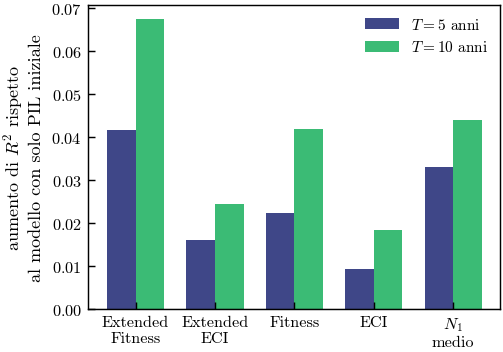

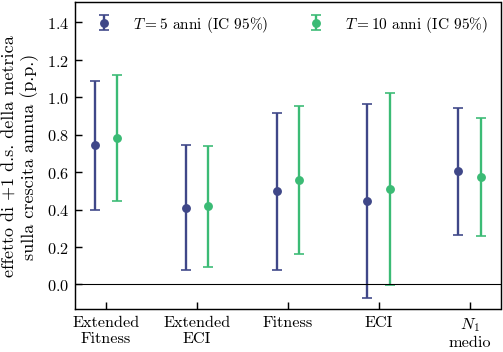

In [6]:
HORIZON_COLOR = {5: SEQ_CMAP(0.25), 10: SEQ_CMAP(0.8)}
single = res[res["modello"].isin([v[1] for v in METRICS.values()])]
names = [v[1] for v in METRICS.values()]
x = np.arange(len(names))
# etichette su due righe per non sovrapporle
ticks = [r"$N_1$" + "\nmedio" if n == "N1 medio" else n.replace(" ", "\n") for n in names]

fig, ax = plt.subplots(figsize=figsize(*SINGLE))
for j, T in enumerate(HORIZONS):
    s = single[single["T"] == T].set_index("modello").reindex(names)
    ax.bar(x + (j - 0.5) * 0.36, s["dR2"], width=0.36, color=HORIZON_COLOR[T], label=f"$T = {T}$ anni")
ax.set_xticks(x); ax.set_xticklabels(ticks)
ax.set_ylabel("aumento di $R^2$ rispetto\nal modello con solo PIL iniziale")
ax.axhline(0, color="k", lw=0.6)
ax.legend(loc="upper right")
fig.tight_layout()
if SAVE_FIGS:
    save_fig(fig, FIG_DIR / "delta_R2")
plt.show()

fig, ax = plt.subplots(figsize=figsize(*SINGLE))
for j, T in enumerate(HORIZONS):
    s = single[single["T"] == T].set_index("modello").reindex(names)
    b = [s.loc[n, f"b_{k}"] for k, n in zip(METRICS, names)]
    e = [1.96 * s.loc[n, f"se_{k}"] for k, n in zip(METRICS, names)]
    ax.errorbar(x + (j - 0.5) * 0.25, b, yerr=e, fmt="o", color=HORIZON_COLOR[T], capsize=2.5, label=f"$T = {T}$ anni (IC 95%)")
ax.axhline(0, color="k", lw=0.6)
ax.set_xticks(x); ax.set_xticklabels(ticks)
ax.set_ylabel("effetto di +1 d.s. della metrica\nsulla crescita annua (p.p.)")
lo, hi = ax.get_ylim()
ax.set_ylim(lo, hi + 0.25 * (hi - lo))
ax.legend(loc="upper center", ncol=2)
fig.tight_layout()
if SAVE_FIGS:
    save_fig(fig, FIG_DIR / "coefficienti")
plt.show()

### Added-variable plot

Crescita e metrica, entrambe depurate da PIL iniziale ed effetti di periodo (teorema di Frisch–Waugh–Lovell):
la pendenza della retta è esattamente $\beta_2$.

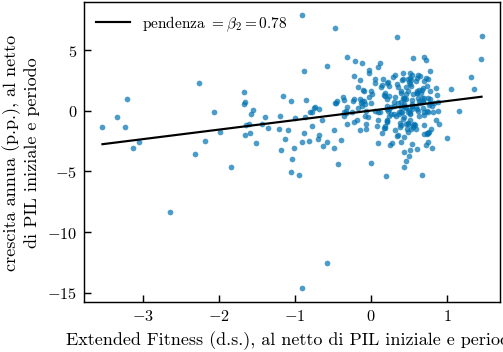

In [7]:
AV_METRIC, AV_T = "extended_fitness", 10

d = panels[AV_T]
rg = residualize(d, "g", ["lny0"], ["period"])
rz = residualize(d, f"z_{AV_METRIC}", ["lny0"], ["period"])
slope = np.polyfit(rz, rg, 1)

fig, ax = plt.subplots(figsize=figsize(*SINGLE))
ax.scatter(rz, rg, s=10, color=PALETTE[4], alpha=0.7, lw=0)
xx = np.linspace(rz.min(), rz.max(), 50)
ax.plot(xx, np.polyval(slope, xx), color="k", lw=1.2, label=rf"pendenza $= \beta_2 = {slope[0]:.2f}$")
ax.set_xlabel(f"{METRICS[AV_METRIC][1]} (d.s.), al netto di PIL iniziale e periodo")
ax.set_ylabel("crescita annua (p.p.), al netto\ndi PIL iniziale e periodo")
ax.legend(loc="upper left")
fig.tight_layout()
if SAVE_FIGS:
    save_fig(fig, FIG_DIR / f"added_variable_{AV_METRIC}_T{AV_T}")
plt.show()

### Piano fitness–PIL

Schema del *selective predictability scheme* (Cristelli et al. 2015). Per ogni paese e anno si prende lo spostamento nel piano
($\ln F$ fitness estesa, $\ln y$ PIL pro capite) dopo `STEP` anni (tutti gli anni disponibili come punti di partenza).
Su una griglia regolare si stimano, con un kernel gaussiano (larghezza `H` in d.s. delle coordinate):
- lo **spostamento medio** (frecce);
- la **dispersione** degli spostamenti intorno a quello medio (sfondo), in d.s. degli spostamenti:
  bassa = paesi vicini si muovono allo stesso modo, evoluzione prevedibile (**regime laminare**);
  alta = paesi vicini vanno in direzioni diverse (**regime caotico**). La linea scura è la soglia `DISP_LAMINARE`.

Le linee tratteggiate (mediane di $\ln F$ e $\ln y$) dividono il piano nei quattro quadranti.

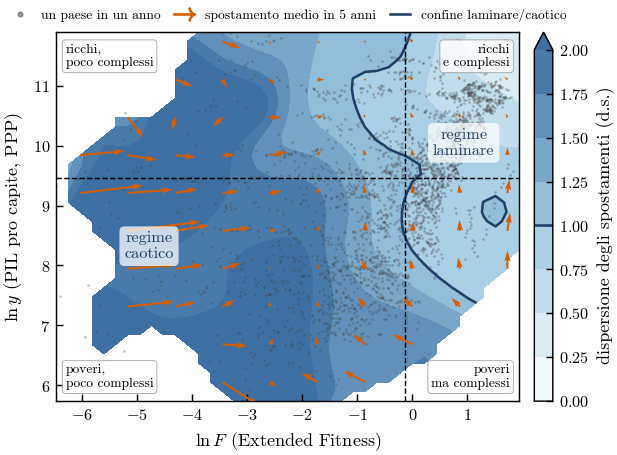

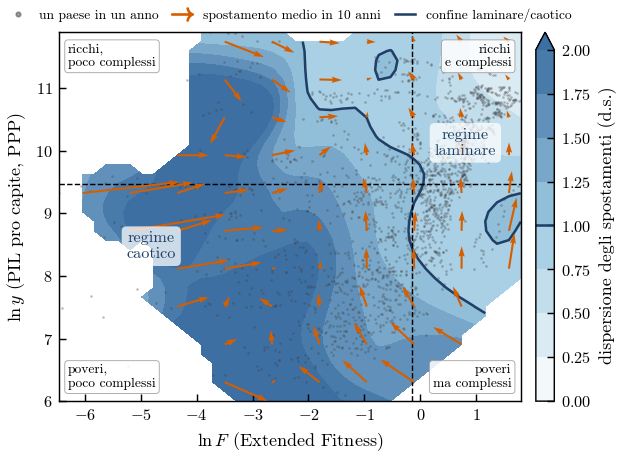

In [8]:
from matplotlib.lines import Line2D
from matplotlib.colors import LinearSegmentedColormap

FIELD_METRIC = "extended_fitness"
STEPS = (5, 10)          # orizzonte degli spostamenti (anni): una figura per ciascuno
H = 0.35                 # larghezza del kernel gaussiano, in d.s. delle coordinate del piano
NGRID = 40               # risoluzione della griglia su cui si stima il campo
MIN_WEIGHT = 4.0         # peso minimo (~ numero efficace di osservazioni) per mostrare un punto della griglia
DISP_LAMINARE = 1.0      # soglia di dispersione che separa regime laminare e caotico
ARROW_EVERY = 4          # una freccia ogni ARROW_EVERY punti della griglia

mm = metrics_wide[FIELD_METRIC].rename("F").to_frame().join(pwt[["lny", "pop"]], how="inner").dropna()
mm = mm[mm["pop"] >= MIN_POP]
mm["lnF"] = np.log(mm["F"])
x_med, y_med = mm["lnF"].median(), mm["lny"].median()      # divisione in quadranti
DISP_CMAP = LinearSegmentedColormap.from_list("disp", ["#ffffff", "#9ecae1", "#3d6fa3"])

def campo(step):
    """Spostamento medio e dispersione degli spostamenti a `step` anni, stimati con un kernel gaussiano su una griglia."""
    nxt = mm[["lnF", "lny"]].rename(lambda t: t - step, level="year")
    P = mm[["lnF", "lny"]].join(nxt, rsuffix="1", how="inner")
    x, y = P["lnF"].to_numpy(), P["lny"].to_numpy()
    dx, dy = (P["lnF1"] - P["lnF"]).to_numpy(), (P["lny1"] - P["lny"]).to_numpy()
    GX, GY = np.meshgrid(np.linspace(x.min(), x.max(), NGRID), np.linspace(y.min(), y.max(), NGRID))
    d2 = ((GX.ravel()[:, None] - x) / x.std()) ** 2 + ((GY.ravel()[:, None] - y) / y.std()) ** 2
    W = np.exp(-d2 / (2 * H ** 2))
    sw = W.sum(axis=1)
    mdx, mdy = W @ dx / sw, W @ dy / sw
    # dispersione: distanza quadratica media dei singoli spostamenti da quello medio (spostamenti in d.s.)
    disp = np.sqrt((W * (((dx - mdx[:, None]) / dx.std()) ** 2 + ((dy - mdy[:, None]) / dy.std()) ** 2)).sum(axis=1) / sw)
    ok = sw >= MIN_WEIGHT
    f = lambda v: np.where(ok, v, np.nan).reshape(GX.shape)
    return x, y, GX, GY, f(mdx), f(mdy), f(disp)

QUADRANTI = {(0, 1): "ricchi,\npoco complessi", (1, 1): "ricchi\ne complessi",
             (0, 0): "poveri,\npoco complessi", (1, 0): "poveri\nma complessi"}

for STEP in STEPS:
    x, y, GX, GY, U, V, disp = campo(STEP)
    fig, ax = plt.subplots(figsize=figsize(0.85, 0.75))
    cf = ax.contourf(GX, GY, disp, levels=np.linspace(0, 2, 9), cmap=DISP_CMAP, extend="max", zorder=0)
    ax.contour(GX, GY, disp, levels=[DISP_LAMINARE], colors="#1f3f66", linewidths=1.4, zorder=2)
    ax.scatter(x, y, s=2, color="0.25", alpha=0.35, lw=0, zorder=1)
    s = (slice(ARROW_EVERY // 2, None, ARROW_EVERY),) * 2
    ax.quiver(GX[s], GY[s], U[s], V[s], angles="xy", scale_units="xy", scale=1, color=PALETTE[6], width=0.0045, zorder=4)
    ax.axvline(x_med, color="k", ls="--", lw=0.8, zorder=3)
    ax.axhline(y_med, color="k", ls="--", lw=0.8, zorder=3)
    for (i, j), txt in QUADRANTI.items():
        ax.text(0.02 if i == 0 else 0.98, 0.03 if j == 0 else 0.97, txt, transform=ax.transAxes, fontsize=7.5,
                ha="left" if i == 0 else "right", va="bottom" if j == 0 else "top", zorder=5,
                bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="0.6", lw=0.5, alpha=0.85))
    ax.set_xlabel(rf"$\ln F$ ({METRICS[FIELD_METRIC][1]})")
    ax.set_ylabel(r"$\ln y$ (PIL pro capite, PPP)")
    cb = fig.colorbar(cf, ax=ax, fraction=0.05, pad=0.03)
    cb.set_label("dispersione degli spostamenti (d.s.)")
    cb.ax.axhline(DISP_LAMINARE, color="#1f3f66", lw=1.4)
    # nomi dei due regimi, dentro le rispettive zone
    for xa, ya, txt in ((0.20, 0.42, "regime\ncaotico"), (0.88, 0.70, "regime\nlaminare")):
        ax.text(xa, ya, txt, transform=ax.transAxes, ha="center", va="center", fontsize=9, color="#1f3f66",
                fontweight="bold", zorder=5, bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="none", alpha=0.75))
    dot = Line2D([], [], color="0.25", alpha=0.5, marker="o", ms=2.5, ls="")
    arrow = Line2D([], [], color=PALETTE[6], marker=r"$\rightarrow$", ms=12, ls="")
    border = Line2D([], [], color="#1f3f66", lw=1.4)
    ax.legend([dot, arrow, border], ["un paese in un anno", f"spostamento medio in {STEP} anni", "confine laminare/caotico"],
              loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=3, columnspacing=1.0, handlelength=1.5, fontsize=7.5)
    fig.tight_layout()
    if SAVE_FIGS:
        save_fig(fig, FIG_DIR / f"piano_fitness_pil_{FIELD_METRIC}_{STEP}_anni")
    plt.show()